# Student Performance Analytics - walkthrough
Synthetic university results data (1,000 students, 5 branches, 2 batches, 6 semesters, 24,000 course results).
**Questions:** Where does a student rank in their branch? Which factors move CGPA? Which courses are hardest? Can we flag at-risk students after semester 2?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib, json
from scipy import stats
sns.set_theme(style="whitegrid"); pd.options.display.float_format = "{:.2f}".format
P = "../data/processed/"
S = pd.read_csv(P+"student_summary.csv"); R = pd.read_csv(P+"results_clean.csv")
SEM = pd.read_csv(P+"student_semester.csv"); D = pd.read_csv(P+"course_difficulty.csv"); ML = pd.read_csv(P+"student_ml_insights.csv")
S.shape, R.shape

((1000, 26), (24000, 13))

## 1. Data quality (from the cleaning step)

In [2]:
print(open('../outputs/data_quality_report.md').read())

# Data quality report

- Loaded raw: students=1010, results=24040, courses=88
- Standardised 101 non-canonical branch labels (case, spaces, long names)
- Standardised 100 gender labels
- Removed 10 exact duplicate student rows
- Imputed 30 missing board_pct with the branch median (flagged in board_pct_imputed)
- Removed 40 duplicate (student, course) result rows
- Recomputed 240 missing total_marks as internal + external
- Imputed 600 missing attendance values with the student's semester mean (flagged)
- Grade validation: 0 rows where stored grade != grade derived from marks
- Integrity checks passed: marks/attendance within range, no orphan keys
- Built tables: students=1000, results=24000, student_semester=6000, student_summary=1000, courses=88



## 2. Result-Hub lookup: rank, percentile and cohort position

In [3]:
def result_hub(eid):
    r = S[S.enrollment_no == eid].iloc[0]
    print(f"{eid} | {r.branch} batch {r.batch}\nCGPA {r.cgpa:.2f} | rank {r.branch_rank}/{r.cohort_size} | Top {r.top_percent}% | percentile {r.percentile}")
    print("SGPA by semester:", [r[f'sgpa_s{i}'] for i in range(1,7)])
result_hub("2022UEC0094")

2022UEC0094 | ECE batch 2022
CGPA 8.67 | rank 22/100 | Top 22% | percentile 79.0
SGPA by semester: [np.float64(9.14), np.float64(8.29), np.float64(8.57), np.float64(8.86), np.float64(8.57), np.float64(8.57)]


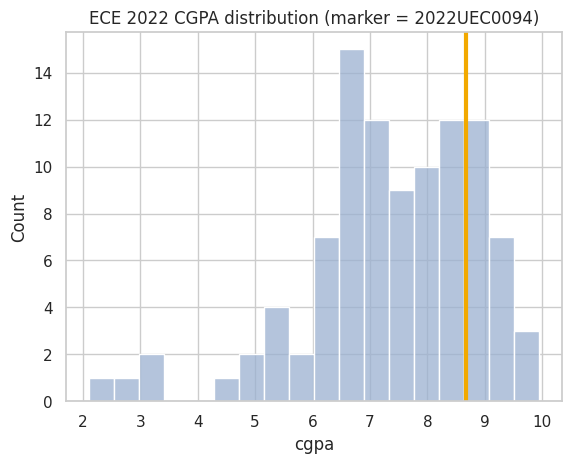

In [4]:
coh = S[(S.branch=="ECE")&(S.batch==2022)]
ax = sns.histplot(coh.cgpa, bins=18, color="#9bb1d1"); ax.axvline(8.67, color="#f2a900", lw=3); ax.set_title("ECE 2022 CGPA distribution (marker = 2022UEC0094)"); plt.show()

## 3. Branch comparison and statistical test

        count  mean  median  std
branch                          
CSE       200  7.69    7.80 1.42
ECE       200  7.55    7.68 1.38
EE        200  7.34    7.48 1.40
IT        200  7.68    7.88 1.18
ME        200  7.25    7.38 1.37
F_onewayResult(statistic=np.float64(4.283018588623957), pvalue=np.float64(0.0019301038766992066))


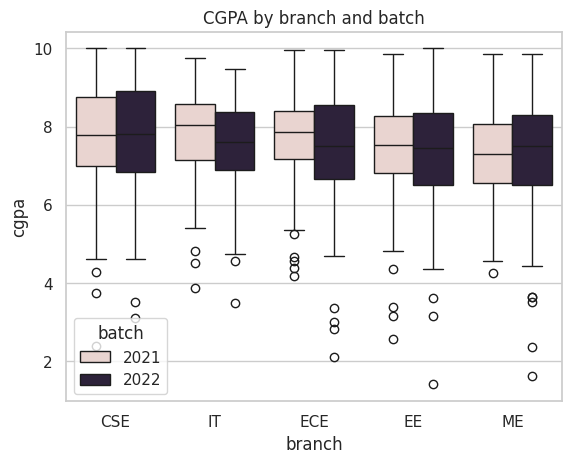

In [5]:
print(S.groupby('branch').cgpa.agg(['count','mean','median','std']))
print(stats.f_oneway(*[g.cgpa.values for _, g in S.groupby('branch')]))
sns.boxplot(data=S, x='branch', y='cgpa', hue='batch'); plt.title('CGPA by branch and batch'); plt.show()

## 4. Drivers of CGPA

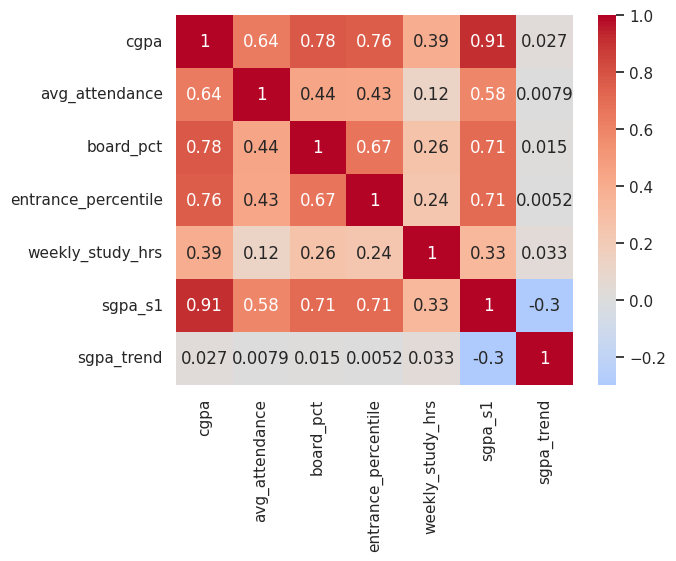

,students,avg_cgpa,avg_backlogs
att_band,,,
<65,36,5.20,3.28
65-75,312,6.77,0.84
75-85,515,7.73,0.21
85+,137,8.92,0.02


In [6]:
cols = ['cgpa','avg_attendance','board_pct','entrance_percentile','weekly_study_hrs','sgpa_s1','sgpa_trend']
sns.heatmap(S[cols].corr(), annot=True, cmap='coolwarm', center=0); plt.show()
S['att_band'] = pd.cut(S.avg_attendance, [0,65,75,85,100], labels=['<65','65-75','75-85','85+'])
S.groupby('att_band', observed=True).agg(students=('cgpa','size'), avg_cgpa=('cgpa','mean'), avg_backlogs=('total_backlogs','mean'))

## 5. Course difficulty (index = 45% low grade point, 35% fail rate, 20% mark spread)

In [7]:
D.sort_values('difficulty_index', ascending=False)[['course_name','branch_scope','semester','avg_gp','fail_rate','difficulty_index']].head(10)

,course_name,branch_scope,semester,avg_gp,fail_rate,difficulty_index
46,Power Systems-I,EE,4,6.24,0.09,97.40
33,Control Systems,ECE,5,6.39,0.09,92.93
52,Power Systems-II,EE,6,6.39,0.06,84.18
50,Power Electronics,EE,5,6.50,0.06,81.36
80,Machine Design,ME,5,6.41,0.06,80.34
14,Database Systems,CSE,4,6.72,0.06,78.61
78,Manufacturing Processes,ME,4,6.62,0.05,77.52
44,Network Analysis,EE,4,6.67,0.06,76.45
22,Software Engineering,CSE,6,6.78,0.05,76.24
77,Heat Transfer,ME,4,6.53,0.06,76.13


## 6. Early-warning model (features known after semester 2 only)

In [8]:
m = json.load(open('../outputs/ml_metrics.json'))
print('Best regressor:', m['best_regressor'], m['regression_holdout'][m['best_regressor']])
print('Best classifier:', m['best_classifier'], m['classification'][m['best_classifier']])
pd.read_csv('../outputs/model_comparison_regression.csv')

Best regressor: Ridge {'rmse': 0.5457333551069745, 'mae': 0.40511184009195433, 'r2': 0.8611543395334005}
Best classifier: Logistic Regression {'cv_auc': 0.9569, 'test_auc': 0.9709, 'precision': 0.8028, 'recall': 0.9048, 'f1': 0.8507}


,model,cv_rmse,cv_rmse_std,cv_r2
0,Ridge,0.52,0.02,0.85
1,Gradient Boosting,0.55,0.03,0.84
2,Random Forest,0.55,0.02,0.83
3,Baseline (mean),1.36,0.09,-0.01


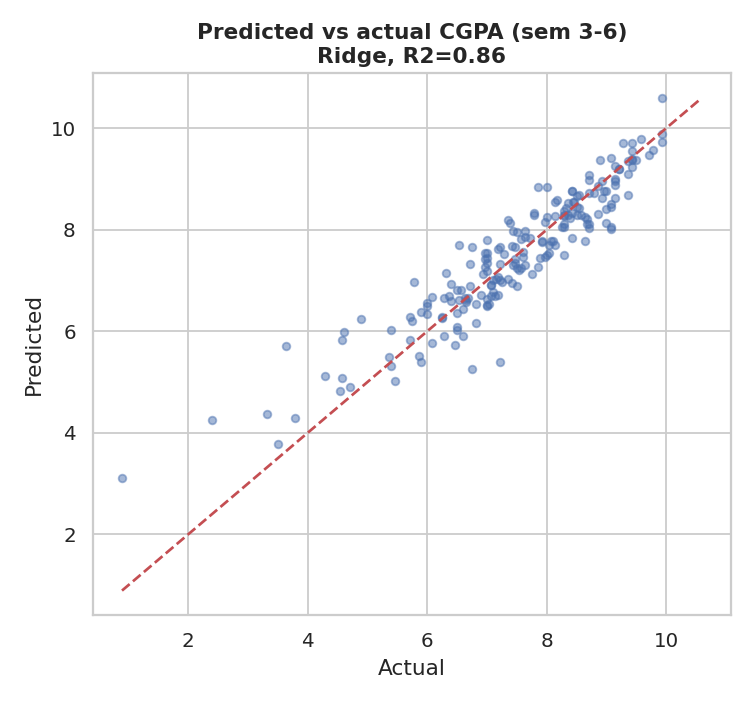

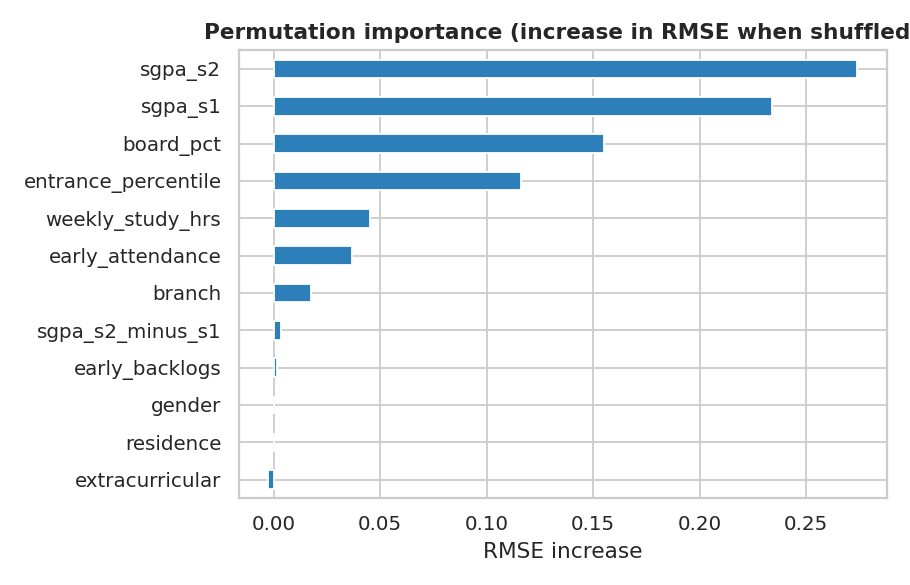

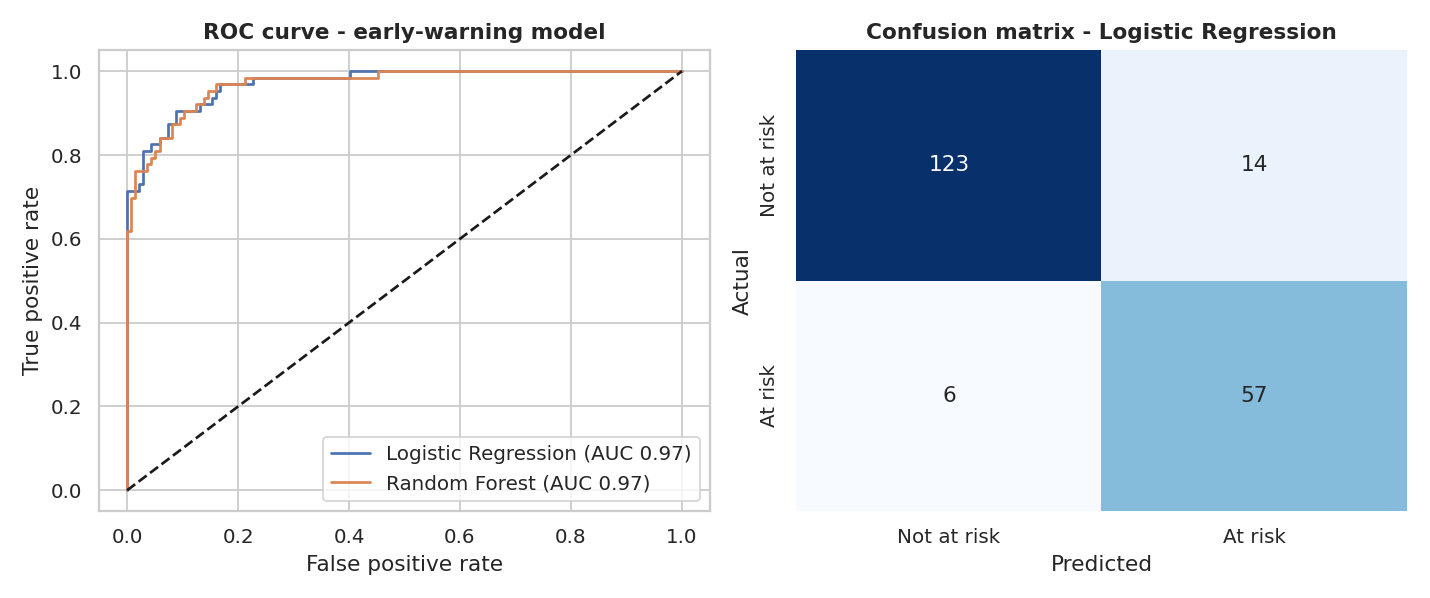

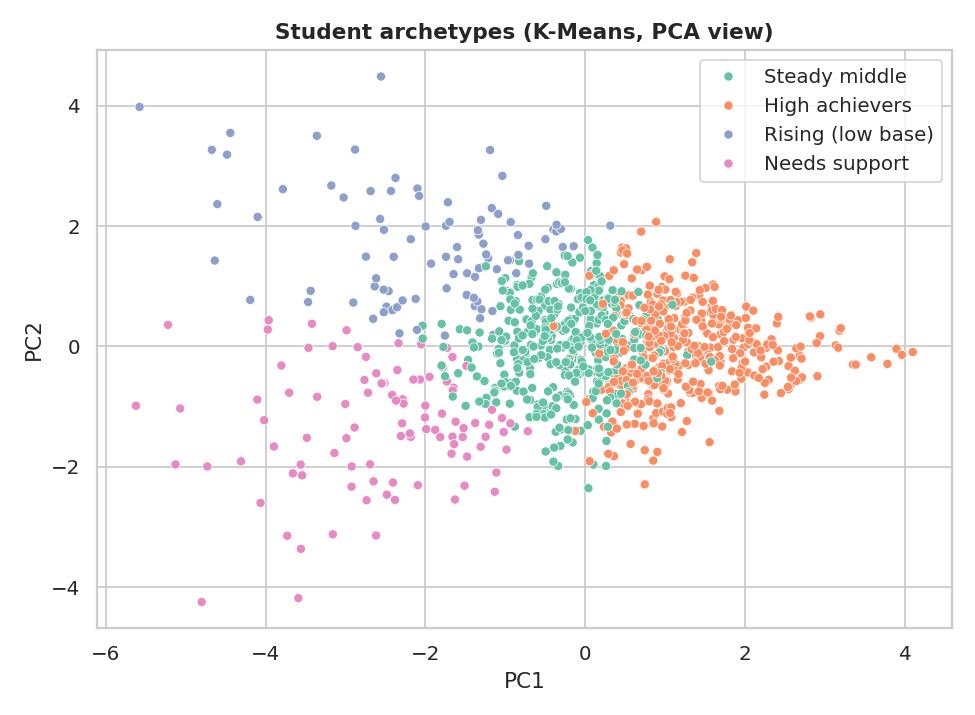

In [9]:
from IPython.display import Image, display
for f in ['10_pred_vs_actual.png','11_feature_importance.png','12_classification_roc_confusion.png','13_student_clusters.png']:
    display(Image('../reports/figures/'+f, width=640))

In [10]:
# Do the risk bands line up with what actually happened?
x = S.merge(ML, on='enrollment_no')
x.groupby('risk_band', observed=True).agg(students=('cgpa','size'), actual_cgpa_s3_6=('target_cgpa_s3_6','mean'), pct_actually_at_risk=('at_risk','mean'))

,students,actual_cgpa_s3_6,pct_actually_at_risk
risk_band,,,
High,337,6.04,0.81
Low,574,8.33,0.03
Medium,89,7.21,0.28


## 7. Takeaways
Attendance, board marks and early SGPA explain most of the variation in later CGPA; branch, gender and hostel status matter far less. A linear model beats boosted trees here, so the simpler, explainable model wins. See `reports/insights.md` for the full write-up and caveats.